# Assignment 3 — Part B
## DashMart: KNN regression and a delivery promise

### Q1 — Load the export as text

The original strings are kept so mixed representations can be inspected before conversion.

In [2]:
# Q1
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler

DATA_PATH = Path("raw_data/dashmart_delivery_times_raw.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("dashmart_delivery_times_raw.csv")

raw_b = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)

print("Shape:", raw_b.shape)
for column_name, format_function in [
    ("order_hour", lambda value: "12-hour AM/PM" if re.search(r"\b(am|pm)\b", value, re.I) else ("clock HH:MM" if ":" in value else "numeric hour")),
    ("distance_km", lambda value: "km suffix" if value.strip().lower().endswith("km") else ("metre suffix" if value.strip().lower().endswith("m") else "plain number")),
    ("delivery_minutes", lambda value: "h:mm:ss" if ":" in value else ("min suffix" if "min" in value.lower() else "plain decimal"))
]:
    print(f"\n{column_name} formats:")
    print(raw_b[column_name].map(format_function).value_counts().to_string())
    print("Examples:", raw_b[column_name].drop_duplicates().head(12).tolist())

Shape: (2430, 11)

order_hour formats:
order_hour
numeric hour     1766
12-hour AM/PM     351
clock HH:MM       313
Examples: ['14', '22:00', '18', '17', '9', '22', '20:00', '21', '23', '20', '16', '19']

distance_km formats:
distance_km
plain number    1638
km suffix        410
metre suffix     382
Examples: ['0.74', '0.9 km', '1.84', '1.11', '210 m', '0.3 km', '690 m', '1.31', '1.33', '2.44 km', '1.76', '0.76']

delivery_minutes formats:
delivery_minutes
plain decimal    2002
h:mm:ss           275
min suffix        153
Examples: ['6.3', '13.1', '17.0', '13.2', '8.0', '11.8', '19.1', '14.2', '23.5', '21.5', '8.3', '14.4 min']


### Q2 — Standardise stores and parse the order hour

The parser accepts numeric hours, `HH:MM`, and 12-hour values. For example, 8 PM becomes 20 and 12 AM becomes 0.

In [3]:
# Q2
b_work = raw_b.copy()

def parse_order_hour(value):
    text_value = str(value).strip().upper()
    if not text_value:
        return np.nan
    match = re.fullmatch(r"(\d{1,2})(?::\d{2}(?::\d{2})?)?\s*(AM|PM)?", text_value)
    if not match:
        return np.nan
    hour_value = int(match.group(1))
    suffix = match.group(2)
    if suffix == "AM":
        return 0 if hour_value == 12 else hour_value
    if suffix == "PM":
        return 12 if hour_value == 12 else hour_value + 12
    return hour_value if 0 <= hour_value <= 23 else np.nan

b_work["store"] = (
    b_work["store"].astype(str).str.strip().str.lower()
    .str.replace(r"[\s-]+", "-", regex=True)
)
store_names = {
    "dm-kharghar": "DM-Kharghar",
    "dm-vashi": "DM-Vashi",
    "dm-nerul": "DM-Nerul",
    "dm-panvel": "DM-Panvel"
}
b_work["store"] = b_work["store"].map(store_names)
b_work["order_hour"] = b_work["order_hour"].map(parse_order_hour)

print("Stores:", sorted(b_work["store"].dropna().unique()))
print("Parsed hour range:", b_work["order_hour"].min(), "to", b_work["order_hour"].max())
print("Examples:")
display(pd.DataFrame({
    "raw": ["8 PM", "12 AM", "12 PM", "20:00", "00:00"],
    "hour": [parse_order_hour(value) for value in ["8 PM", "12 AM", "12 PM", "20:00", "00:00"]]
}))
print("Interpretation: each order hour is represented by one integer from 0 through 23.")

Stores: ['DM-Kharghar', 'DM-Nerul', 'DM-Panvel', 'DM-Vashi']
Parsed hour range: 0 to 23
Examples:


,raw,hour
0,8 PM,20
1,12 AM,0
2,12 PM,12
3,20:00,20
4,00:00,0


Interpretation: each order hour is represented by one integer from 0 through 23.


### Q3 — Convert distances to kilometres

A value with a `km` suffix is already in kilometres; a value with an `m` suffix is divided by 1,000.

In [4]:
# Q3
def parse_distance_km(value):
    text_value = str(value).strip().lower().replace(",", "")
    if not text_value:
        return np.nan
    try:
        if text_value.endswith("km"):
            return float(text_value[:-2].strip())
        if text_value.endswith("m"):
            return float(text_value[:-1].strip()) / 1000
        return float(text_value)
    except ValueError:
        return np.nan

distance_examples_b = raw_b.loc[
    raw_b["distance_km"].str.contains(r"km|m", case=False, regex=True),
    "distance_km"
].drop_duplicates().head(5)
distance_example_table_b = pd.DataFrame({
    "Before": distance_examples_b.to_list(),
    "After (km)": [parse_distance_km(value) for value in distance_examples_b]
})
b_work["distance_km"] = b_work["distance_km"].map(parse_distance_km)
display(distance_example_table_b)
print("Interpretation: the model receives one distance unit, so 850 m is represented as 0.85 km.")

,Before,After (km)
0,0.9 km,0.90
1,210 m,0.21
2,0.3 km,0.30
3,690 m,0.69
4,2.44 km,2.44


Interpretation: the model receives one distance unit, so 850 m is represented as 0.85 km.


### Q4 — Convert delivery duration and flag impossible values

`h:mm:ss` is converted to minutes as `hours × 60 + minutes + seconds / 60`. A delivered order must take more than 0 and no more than 120 minutes; negative, zero and multi-hour values are inconsistent with a completed delivery record.

In [5]:
# Q4
def parse_delivery_minutes(value):
    text_value = str(value).strip().lower()
    if not text_value:
        return np.nan
    text_value = text_value.replace("min", "").strip()
    try:
        if ":" in text_value:
            parts = [float(part) for part in text_value.split(":")]
            if len(parts) == 3:
                hours, minutes, seconds = parts
                return hours * 60 + minutes + seconds / 60
            if len(parts) == 2:
                minutes, seconds = parts
                return minutes + seconds / 60
            return np.nan
        return float(text_value)
    except ValueError:
        return np.nan

b_work["delivery_minutes"] = b_work["delivery_minutes"].map(parse_delivery_minutes)
invalid_delivery_mask_b = (
    b_work["delivery_minutes"].le(0)
    | b_work["delivery_minutes"].gt(120)
    | b_work["delivery_minutes"].isna()
)
invalid_delivery_rows_b = b_work.loc[invalid_delivery_mask_b, [
    "order_id", "delivery_minutes"
]].copy()

print("Converted examples:")
display(pd.DataFrame({
    "Raw": ["14.6 min", "0:14:36", "1:02:30"],
    "Minutes": [parse_delivery_minutes(value) for value in ["14.6 min", "0:14:36", "1:02:30"]]
}))
print(f"Impossible rows found before duplicate removal: {int(invalid_delivery_mask_b.sum())}")
display(invalid_delivery_rows_b)
print("Interpretation: these values are not credible delivered-order durations; replacing them with a plausible time would invent a target, so the rows are excluded.")

Converted examples:


,Raw,Minutes
0,14.6 min,14.6
1,0:14:36,14.6
2,1:02:30,62.5


Impossible rows found before duplicate removal: 9


,order_id,delivery_minutes
512,DMO700646,-5.0
545,DMO701295,-5.0
623,DMO701976,0.0
733,DMO700195,1440.0
969,DMO700756,987.5
1281,DMO701688,1440.0
1667,DMO701526,412.0
1807,DMO701557,987.5
2389,DMO701489,1440.0


Interpretation: these values are not credible delivered-order durations; replacing them with a plausible time would invent a target, so the rows are excluded.


### Q5 — Convert the remaining fields and remove duplicates

Rain is encoded as 0/1, rupee values are parsed as numbers, and `new joiner` becomes 0 months. Duplicate removal is based on exact raw rows.

In [6]:
# Q5
def to_number(values):
    cleaned = values.astype(str).str.strip().str.replace(",", "", regex=False)
    cleaned = cleaned.mask(cleaned.str.lower().isin({"", "na", "n/a", "?", "not measured", "nan", "none", "null"}))
    return pd.to_numeric(cleaned, errors="coerce")

def parse_rupees(value):
    text_value = str(value).strip().replace(",", "")
    if not text_value:
        return np.nan
    text_value = re.sub(r"[^0-9.\-]", "", text_value)
    try:
        return float(text_value)
    except ValueError:
        return np.nan

b_work["order_value_rs"] = b_work["order_value_rs"].map(parse_rupees)
b_work["store_queue"] = to_number(b_work["store_queue"])
b_work["items"] = to_number(b_work["items"])
b_work["drop_floor"] = to_number(b_work["drop_floor"])
b_work["raining"] = (
    b_work["raining"].astype(str).str.strip().str.lower()
    .map({"y": 1, "yes": 1, "1": 1, "true": 1, "n": 0, "no": 0, "0": 0, "false": 0})
)
b_work["rider_experience_months"] = (
    b_work["rider_experience_months"].astype(str).str.strip().str.lower()
    .replace({"new joiner": "0"})
)
b_work["rider_experience_months"] = to_number(b_work["rider_experience_months"])

duplicates_b = int(raw_b.duplicated(keep="first").sum())
rows_before_b = len(b_work)
b_work = b_work.loc[~raw_b.duplicated(keep="first")].copy()
rows_after_dedup_b = len(b_work)

invalid_after_dedup_b = (
    b_work["delivery_minutes"].le(0)
    | b_work["delivery_minutes"].gt(120)
    | b_work["delivery_minutes"].isna()
)
invalid_count_b = int(invalid_after_dedup_b.sum())
b_work = b_work.loc[~invalid_after_dedup_b].copy().reset_index(drop=True)

print(f"Exact duplicates removed: {duplicates_b}")
print(f"Rows before/after duplicate removal: {rows_before_b:,} / {rows_after_dedup_b:,}")
print(f"Impossible delivery rows removed after deduplication: {invalid_count_b}")
print(f"Rows retained: {len(b_work):,}")
print("Interpretation: duplicate exports and invalid delivery targets are removed without changing the source CSV.")

Exact duplicates removed: 30
Rows before/after duplicate removal: 2,430 / 2,400
Impossible delivery rows removed after deduplication: 9
Rows retained: 2,391
Interpretation: duplicate exports and invalid delivery targets are removed without changing the source CSV.


### Q6 — Report missing values and save the cleaned data

Missing predictor values are not filled here. Median imputation is fitted separately within each training fold and then applied to validation or test rows.

In [7]:
# Q6
b_clean = b_work.copy()
missing_b = b_clean.isna().sum().rename("missing_values").to_frame()
display(missing_b)

clean_b_path = Path("clean_data/dashmart_delivery_times_cleaned.csv")
b_clean.to_csv(clean_b_path, index=False)
print(f"Cleaned rows: {len(b_clean):,}")
print(f"Cleaned CSV saved to: {clean_b_path.resolve()}")
print("Imputation plan: median imputation for numeric predictors inside each pipeline; delivery_minutes is never imputed.")
print("Interpretation: store_queue and rider_experience_months contain the remaining missing predictor values and are handled without test leakage.")

,missing_values
order_id,0
store,0
order_hour,0
distance_km,0
items,0
order_value_rs,0
store_queue,40
raining,0
rider_experience_months,43
drop_floor,0


Cleaned rows: 2,391
Cleaned CSV saved to: C:\Users\ACER\Downloads\Ascend\Third_Assignment_Solutions\clean_data\dashmart_delivery_times_cleaned.csv
Imputation plan: median imputation for numeric predictors inside each pipeline; delivery_minutes is never imputed.
Interpretation: store_queue and rider_experience_months contain the remaining missing predictor values and are handled without test leakage.


### Q7 — Delivery-time distribution and current promise

The current flat promise is 15 minutes. A delivered order breaks that promise when actual delivery time is greater than 15 minutes.

,delivery_minutes
count,2391.00
median,14.10
mean,14.70
std,4.57
min,5.00
max,34.70


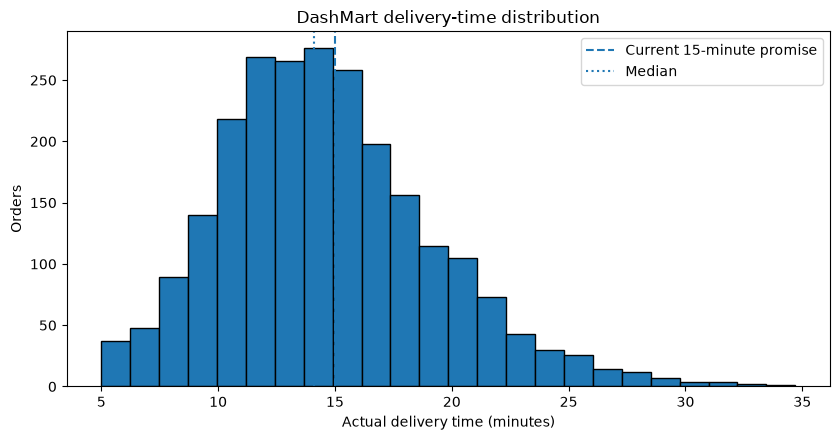

Median: 14.10 min
Mean: 14.70 min
Orders later than 15 minutes: 41.74%
Median relative to promise: 0.90 min earlier than 15 minutes
Interpretation: the median is slightly below 15 minutes, but more than four in ten orders still break the flat promise.


In [8]:
# Q7
delivery_summary_b = b_clean["delivery_minutes"].agg(["count", "median", "mean", "std", "min", "max"]).to_frame("delivery_minutes")
display(delivery_summary_b.round(2))

plt.figure(figsize=(8.5, 4.5))
plt.hist(b_clean["delivery_minutes"], bins=24, edgecolor="black")
plt.axvline(15, linestyle="--", label="Current 15-minute promise")
plt.axvline(b_clean["delivery_minutes"].median(), linestyle=":", label="Median")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Orders")
plt.title("DashMart delivery-time distribution")
plt.legend()
plt.tight_layout()
plt.show()

late_share_all_b = (b_clean["delivery_minutes"] > 15).mean()
median_difference_b = b_clean["delivery_minutes"].median() - 15
print(f"Median: {b_clean['delivery_minutes'].median():.2f} min")
print(f"Mean: {b_clean['delivery_minutes'].mean():.2f} min")
print(f"Orders later than 15 minutes: {late_share_all_b:.2%}")
print(f"Median relative to promise: {abs(median_difference_b):.2f} min earlier than 15 minutes")
print("Interpretation: the median is slightly below 15 minutes, but more than four in ten orders still break the flat promise.")

### Q8 — Train/test split and median baseline

The split is 80/20 with `random_state=42`. The baseline predicts the training-set median for every test order.

In [9]:
# Q8
features_b = [
    "distance_km", "items", "order_value_rs", "store_queue",
    "raining", "rider_experience_months", "drop_floor", "order_hour"
]
X_b = b_clean[features_b].copy()
y_b = b_clean["delivery_minutes"].copy()

X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42
)

baseline_delivery_prediction_b = float(y_b_train.median())
baseline_predictions_b = np.full(len(y_b_test), baseline_delivery_prediction_b)
baseline_mae_b = mean_absolute_error(y_b_test, baseline_predictions_b)

print(f"Training orders: {len(X_b_train):,}; test orders: {len(X_b_test):,}")
print(f"Training median: {baseline_delivery_prediction_b:.2f} minutes")
print(f"Baseline test MAE: {baseline_mae_b:.3f} minutes")
print("Interpretation: every test order receives the same estimate, so this is a simple benchmark rather than an order-specific ETA.")

Training orders: 1,912; test orders: 479
Training median: 14.10 minutes
Baseline test MAE: 3.519 minutes
Interpretation: every test order receives the same estimate, so this is a simple benchmark rather than an order-specific ETA.


### Q9 — KNN regression without scaling

The raw model uses the eight listed numeric predictors, median imputation and k=7. RMSE and R² are reported alongside MAE.

In [10]:
# Q9
def regression_metrics(model, features, target):
    predictions = model.predict(features)
    return {
        "MAE": mean_absolute_error(target, predictions),
        "RMSE": mean_squared_error(target, predictions) ** 0.5,
        "R²": r2_score(target, predictions)
    }

raw_knn_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("knn", KNeighborsRegressor(n_neighbors=7))
])
raw_knn_b.fit(X_b_train, y_b_train)
raw_metrics_b = regression_metrics(raw_knn_b, X_b_test, y_b_test)

display(pd.DataFrame([
    {"Model": "Training-median baseline", "MAE": baseline_mae_b, **{
        "RMSE": mean_squared_error(y_b_test, baseline_predictions_b) ** 0.5,
        "R²": r2_score(y_b_test, baseline_predictions_b)
    }},
    {"Model": "Raw KNN (k=7)", **raw_metrics_b}
]).set_index("Model").round(4))
print("Interpretation: a negative or near-zero R² means the model explains little of the test-set variation and may be no better than a constant prediction.")

,MAE,RMSE,R²
Model,,,
Training-median baseline,3.5186,4.5260,-0.0279
Raw KNN (k=7),3.7214,4.6703,-0.0945


Interpretation: a negative or near-zero R² means the model explains little of the test-set variation and may be no better than a constant prediction.


### Q10 — Compare raw, StandardScaler and MinMaxScaler

Scaling is fitted on the training split only. The raw model is particularly vulnerable to the range of `order_value_rs`, which spans thousands of rupees but has almost no linear relationship with delivery time.

In [11]:
# Q10
standard_knn_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=7))
])
minmax_knn_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=7))
])

standard_knn_b.fit(X_b_train, y_b_train)
minmax_knn_b.fit(X_b_train, y_b_train)
standard_metrics_b = regression_metrics(standard_knn_b, X_b_test, y_b_test)
minmax_metrics_b = regression_metrics(minmax_knn_b, X_b_test, y_b_test)

scale_comparison_b = pd.DataFrame([
    {"Model": "Raw KNN", **raw_metrics_b},
    {"Model": "StandardScaler KNN", **standard_metrics_b},
    {"Model": "MinMaxScaler KNN", **minmax_metrics_b}
]).set_index("Model")
display(scale_comparison_b.round(4))

print("Feature ranges and relationship with the target:")
feature_profile_b = b_clean[features_b].agg(["min", "max", "std"]).T
feature_profile_b["correlation_with_delivery"] = b_clean[features_b + ["delivery_minutes"]].corr(numeric_only=True)["delivery_minutes"].drop("delivery_minutes")
display(feature_profile_b.sort_values("max", ascending=False))
print("Interpretation: order_value_rs spans ₹60–₹2,129 but its target correlation is close to zero, so raw distance gives a weak feature too much influence.")

,MAE,RMSE,R²
Model,,,
Raw KNN,3.7214,4.6703,-0.0945
StandardScaler KNN,1.7264,2.1652,0.7648
MinMaxScaler KNN,1.7731,2.2163,0.7535


Feature ranges and relationship with the target:


,min,max,std,correlation_with_delivery
order_value_rs,60.0,2129.0,317.584749,0.041138
rider_experience_months,0.0,60.0,8.103670,-0.081141
drop_floor,0.0,29.0,8.716685,0.120450
order_hour,0.0,23.0,5.440242,0.062460
store_queue,0.0,21.0,3.473439,0.315114
items,1.0,16.0,2.429495,0.085460
distance_km,0.2,5.0,0.873798,0.790828
raining,0.0,1.0,0.408252,0.303828


Interpretation: order_value_rs spans ₹60–₹2,129 but its target correlation is close to zero, so raw distance gives a weak feature too much influence.


### Q11 — MAE versus RMSE

MAE is the average absolute error in minutes; RMSE also penalises large misses more heavily because it squares each error before averaging. **MAE** matches the stated “typical error under 2.5 minutes” target.

### Q12 — Choose k by five-fold cross-validation

The training split is divided into five folds. Each candidate pipeline imputes and scales inside its own fold, and the validation score is MAE.

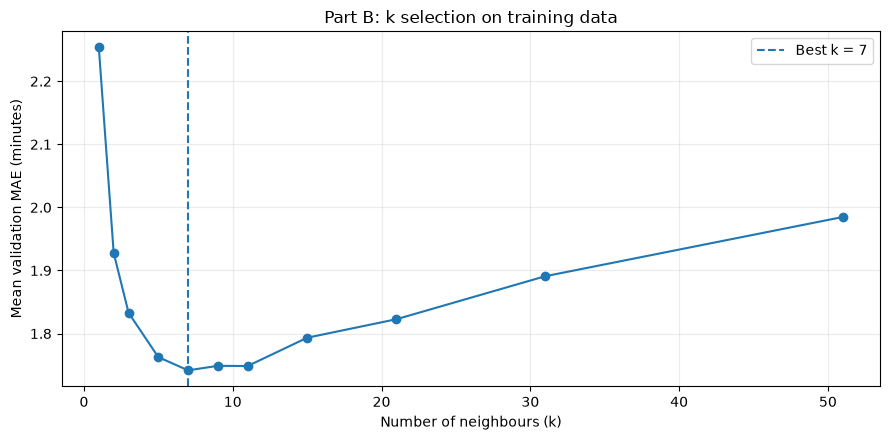

CV results: {1: np.float64(2.254), 2: np.float64(1.928), 3: np.float64(1.833), 5: np.float64(1.763), 7: np.float64(1.742), 9: np.float64(1.749), 11: np.float64(1.749), 15: np.float64(1.793), 21: np.float64(1.823), 31: np.float64(1.891), 51: np.float64(1.985)}
Best k: 7
Interpretation: k=1 is too sensitive to one unusual order (high variance); k=51 averages many less-similar orders (high bias).


In [12]:
# Q12
cv_b = KFold(n_splits=5, shuffle=True, random_state=42)
k_values_b = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv_mae_values_b = []

for neighbour_count in k_values_b:
    candidate = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=neighbour_count))
    ])
    fold_scores = cross_val_score(
        candidate, X_b_train, y_b_train,
        cv=cv_b, scoring="neg_mean_absolute_error", n_jobs=1
    )
    cv_mae_values_b.append(-fold_scores.mean())

best_k_cv_b = k_values_b[int(np.argmin(cv_mae_values_b))]
plt.figure(figsize=(9, 4.5))
plt.plot(k_values_b, cv_mae_values_b, marker="o")
plt.axvline(best_k_cv_b, linestyle="--", label=f"Best k = {best_k_cv_b}")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean validation MAE (minutes)")
plt.title("Part B: k selection on training data")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("CV results:", dict(zip(k_values_b, np.round(cv_mae_values_b, 3))))
print(f"Best k: {best_k_cv_b}")
print("Interpretation: k=1 is too sensitive to one unusual order (high variance); k=51 averages many less-similar orders (high bias).")

### Q13 — Encode hour as a cycle

Hour is periodic: 23:00 and 00:00 are adjacent, not 23 hours apart. Replace it with sine and cosine coordinates and compare the held-out MAE overall and for 23:00–01:59.

In [13]:
# Q13
def add_cyclical_hour(features):
    transformed = features.drop(columns=["order_hour"]).copy()
    transformed["hour_sin"] = np.sin(2 * np.pi * features["order_hour"] / 24)
    transformed["hour_cos"] = np.cos(2 * np.pi * features["order_hour"] / 24)
    return transformed

X_b_cyc = add_cyclical_hour(X_b)
X_b_cyc_train = X_b_cyc.loc[X_b_train.index]
X_b_cyc_test = X_b_cyc.loc[X_b_test.index]

cyclical_knn_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=7))
])
cyclical_knn_b.fit(X_b_cyc_train, y_b_train)

linear_hour_predictions_b = standard_knn_b.predict(X_b_test)
cyclical_hour_predictions_b = cyclical_knn_b.predict(X_b_cyc_test)

late_night_mask_b = b_clean.loc[X_b_test.index, "order_hour"].isin([23, 0, 1])
hour_comparison_b = pd.DataFrame([
    {
        "Encoding": "Integer hour",
        "Overall MAE": mean_absolute_error(y_b_test, linear_hour_predictions_b),
        "23:00–01:59 MAE": mean_absolute_error(y_b_test[late_night_mask_b], linear_hour_predictions_b[late_night_mask_b])
    },
    {
        "Encoding": "Sine/cosine hour",
        "Overall MAE": mean_absolute_error(y_b_test, cyclical_hour_predictions_b),
        "23:00–01:59 MAE": mean_absolute_error(y_b_test[late_night_mask_b], cyclical_hour_predictions_b[late_night_mask_b])
    }
])
display(hour_comparison_b.round(4))
print(f"Late-night test orders: {int(late_night_mask_b.sum())}")
print("Interpretation: cyclical encoding does not improve this split; it would matter more if many orders near midnight shared patterns with orders just after midnight.")

,Encoding,Overall MAE,23:00–01:59 MAE
0,Integer hour,1.7264,1.6922
1,Sine/cosine hour,1.7715,1.7608


Late-night test orders: 31
Interpretation: cyclical encoding does not improve this split; it would matter more if many orders near midnight shared patterns with orders just after midnight.


### Q14 — Tune k and neighbour weights on the cyclical feature set

The feature set keeps distance, items, basket value, queue, rain, rider experience and floor, and replaces integer hour with sine/cosine hour.

In [14]:
# Q14
grid_pipeline_b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])
parameter_grid_b = {
    "knn__n_neighbors": k_values_b,
    "knn__weights": ["uniform", "distance"]
}
grid_search_b = GridSearchCV(
    grid_pipeline_b,
    param_grid=parameter_grid_b,
    scoring="neg_mean_absolute_error",
    cv=cv_b,
    n_jobs=1
)
grid_search_b.fit(X_b_cyc_train, y_b_train)
best_model_b = grid_search_b.best_estimator_
tuned_metrics_b = regression_metrics(best_model_b, X_b_cyc_test, y_b_test)

print("Best settings:", grid_search_b.best_params_)
print(f"Best CV MAE: {-grid_search_b.best_score_:.4f} minutes")
display(pd.DataFrame(tuned_metrics_b, index=["Tuned cyclical KNN"]).round(4))
print("Interpretation: the test MAE is below 2.5 minutes, so the model meets the typical-error target on this held-out split.")

Best settings: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
Best CV MAE: 1.7723 minutes


,MAE,RMSE,R²
Tuned cyclical KNN,1.7554,2.2077,0.7554


Interpretation: the test MAE is below 2.5 minutes, so the model meets the typical-error target on this held-out split.


### Q15 — Remove order value and re-run the search

Basket value may be weakly related to delivery duration. Removing it tests whether an unhelpful dimension is making the neighbourhoods less meaningful.

In [15]:
# Q15
X_b_cyc_train_no_value = X_b_cyc_train.drop(columns=["order_value_rs"])
X_b_cyc_test_no_value = X_b_cyc_test.drop(columns=["order_value_rs"])

grid_search_no_value_b = GridSearchCV(
    grid_pipeline_b,
    param_grid=parameter_grid_b,
    scoring="neg_mean_absolute_error",
    cv=cv_b,
    n_jobs=1
)
grid_search_no_value_b.fit(X_b_cyc_train_no_value, y_b_train)
best_model_no_value_b = grid_search_no_value_b.best_estimator_
no_value_metrics_b = regression_metrics(
    best_model_no_value_b, X_b_cyc_test_no_value, y_b_test
)

print("Best settings without order_value_rs:", grid_search_no_value_b.best_params_)
print(f"CV MAE without order_value_rs: {-grid_search_no_value_b.best_score_:.4f} minutes")
display(pd.DataFrame([
    {"Model": "Tuned with order_value_rs", **tuned_metrics_b},
    {"Model": "Tuned without order_value_rs", **no_value_metrics_b}
]).set_index("Model").round(4))
print("Interpretation: removing order value slightly improves test MAE, which shows that adding a weak feature can dilute similarity in KNN.")

Best settings without order_value_rs: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
CV MAE without order_value_rs: 1.7052 minutes


,MAE,RMSE,R²
Model,,,
Tuned with order_value_rs,1.7554,2.2077,0.7554
Tuned without order_value_rs,1.7397,2.2057,0.7559


Interpretation: removing order value slightly improves test MAE, which shows that adding a weak feature can dilute similarity in KNN.


### Q16 — Predicted versus actual delivery time and error groups

The plot shows test predictions against actual delivery times. The table compares absolute error during rain versus no rain and during peak hours (18:00–21:59) versus all other hours.

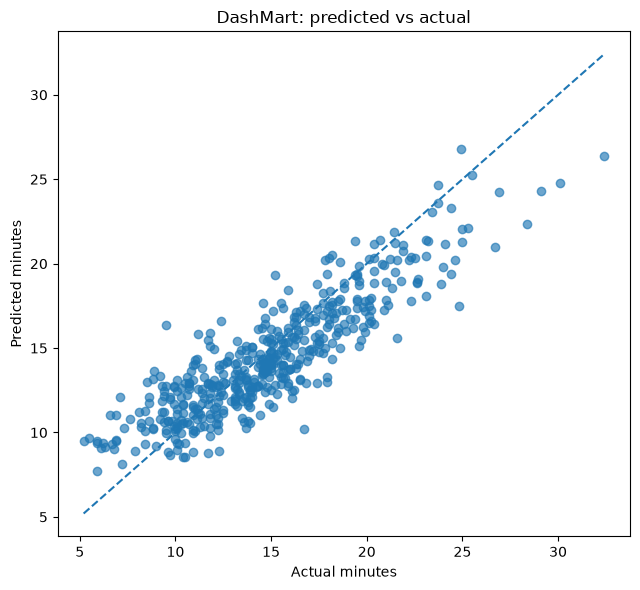

MAE by rain flag (0 = no, 1 = yes):


,count,MAE
raining,,
0,381,1.728
1,98,1.862


MAE by hour group:


,count,MAE
period,,
Other hours,340,1.761
Peak 18:00–21:59,139,1.741


Largest absolute errors:


,order_id,store,order_hour,delivery_minutes,predicted_minutes,absolute_error,distance_km,store_queue
800,DMO701211,DM-Vashi,9,24.8,17.507076,7.292924,2.28,11.0
2164,DMO702174,DM-Panvel,22,9.5,16.366906,6.866906,0.36,2.0
177,DMO702191,DM-Panvel,12,16.7,10.187744,6.512256,0.85,1.0
1697,DMO702109,DM-Nerul,7,28.4,22.338202,6.061798,3.83,4.0
303,DMO702377,DM-Vashi,12,32.4,26.380988,6.019012,4.84,1.0


Interpretation: the largest misses are individual orders where the observed delivery time differs sharply from the local average; the subgroup MAEs show whether rain or peak period changes the typical error.


In [16]:
# Q16
tuned_predictions_b = best_model_b.predict(X_b_cyc_test)
test_errors_b = b_clean.loc[X_b_test.index, [
    "order_id", "store", "order_hour", "raining", "delivery_minutes",
    "distance_km", "store_queue"
]].copy()
test_errors_b["predicted_minutes"] = tuned_predictions_b
test_errors_b["absolute_error"] = np.abs(
    test_errors_b["delivery_minutes"] - test_errors_b["predicted_minutes"]
)

plt.figure(figsize=(6.5, 6))
plt.scatter(test_errors_b["delivery_minutes"], test_errors_b["predicted_minutes"], alpha=0.65)
plot_min_b = min(test_errors_b["delivery_minutes"].min(), test_errors_b["predicted_minutes"].min())
plot_max_b = max(test_errors_b["delivery_minutes"].max(), test_errors_b["predicted_minutes"].max())
plt.plot([plot_min_b, plot_max_b], [plot_min_b, plot_max_b], linestyle="--")
plt.xlabel("Actual minutes")
plt.ylabel("Predicted minutes")
plt.title("DashMart: predicted vs actual")
plt.tight_layout()
plt.show()

test_errors_b["period"] = np.where(
    test_errors_b["order_hour"].between(18, 21),
    "Peak 18:00–21:59", "Other hours"
)
rain_mae_b = test_errors_b.groupby("raining")["absolute_error"].agg(["count", "mean"])
period_mae_b = test_errors_b.groupby("period")["absolute_error"].agg(["count", "mean"])
print("MAE by rain flag (0 = no, 1 = yes):")
display(rain_mae_b.rename(columns={"mean": "MAE"}).round(3))
print("MAE by hour group:")
display(period_mae_b.rename(columns={"mean": "MAE"}).round(3))
print("Largest absolute errors:")
display(test_errors_b.nlargest(5, "absolute_error")[[
    "order_id", "store", "order_hour", "delivery_minutes",
    "predicted_minutes", "absolute_error", "distance_km", "store_queue"
]])
print("Interpretation: the largest misses are individual orders where the observed delivery time differs sharply from the local average; the subgroup MAEs show whether rain or peak period changes the typical error.")

### Q17 — Select a safety buffer

An order is late when its actual delivery time exceeds the predicted time plus the buffer. The smallest listed buffer with at most 10% late orders is selected.

In [17]:
# Q17
buffer_values_b = [0, 2, 3, 4, 5]
buffer_rows_b = []
actual_test_values_b = y_b_test.to_numpy()

for buffer_minutes in buffer_values_b:
    late_mask = actual_test_values_b > (tuned_predictions_b + buffer_minutes)
    buffer_rows_b.append({
        "Buffer (minutes)": buffer_minutes,
        "Late orders": int(late_mask.sum()),
        "Late share": late_mask.mean()
    })

buffer_table_b = pd.DataFrame(buffer_rows_b)
display(buffer_table_b.round(4))
chosen_buffer_b = int(buffer_table_b.loc[
    buffer_table_b["Late share"].le(0.10), "Buffer (minutes)"
].iloc[0])
print(f"Smallest buffer meeting the 10% limit: {chosen_buffer_b} minutes")
print("Interpretation: the selected buffer is the first tested value that keeps late deliveries at or below 10% on the test set.")

,Buffer (minutes),Late orders,Late share
0,0,287,0.5992
1,2,112,0.2338
2,3,52,0.1086
3,4,21,0.0438
4,5,10,0.0209


Smallest buffer meeting the 10% limit: 4 minutes
Interpretation: the selected buffer is the first tested value that keeps late deliveries at or below 10% on the test set.


### Q18 — Predict the specified rainy 8 PM order

The order is 2.4 km away, has 12 items, a ₹1,450 basket, queue 11, rain, a 3-month rider and a 14th-floor drop. Store identity was not supplied, so it is not a predictor in this model.

In [18]:
# Q18
def make_customer_order(raining_value=1):
    customer_order = pd.DataFrame([{
        "distance_km": 2.4,
        "items": 12,
        "order_value_rs": 1450,
        "store_queue": 11,
        "raining": raining_value,
        "rider_experience_months": 3,
        "drop_floor": 14,
        "order_hour": 20
    }])
    return add_cyclical_hour(customer_order)[X_b_cyc.columns]

customer_order_rain_b = make_customer_order(raining_value=1)
customer_prediction_rain_b = float(best_model_b.predict(customer_order_rain_b)[0])
customer_promise_b = customer_prediction_rain_b + chosen_buffer_b

print(f"Predicted delivery time: {customer_prediction_rain_b:.2f} minutes")
print(f"Safety buffer: {chosen_buffer_b} minutes")
print(f"Promise to show: {customer_promise_b:.2f} minutes (about {int(np.ceil(customer_promise_b))} minutes)")
print("Interpretation: the app should show the order-specific prediction plus the test-set buffer, rather than the same 15-minute promise for every customer.")

Predicted delivery time: 23.83 minutes
Safety buffer: 4 minutes
Promise to show: 27.83 minutes (about 28 minutes)
Interpretation: the app should show the order-specific prediction plus the test-set buffer, rather than the same 15-minute promise for every customer.


### Q19 — Inspect the neighbours behind the ETA

The neighbours are retrieved from the fitted KNN model after applying its training-fitted imputer and scaler. Store is shown as context even though it was not used to calculate distance.

In [19]:
# Q19
fitted_imputer_b = best_model_b.named_steps["imputer"]
fitted_scaler_b = best_model_b.named_steps["scaler"]
fitted_knn_b = best_model_b.named_steps["knn"]

transformed_training_b = fitted_scaler_b.transform(
    fitted_imputer_b.transform(X_b_cyc_train)
)
transformed_customer_b = fitted_scaler_b.transform(
    fitted_imputer_b.transform(customer_order_rain_b)
)
neighbour_distances_b, neighbour_positions_b = fitted_knn_b.kneighbors(
    transformed_customer_b, n_neighbors=7
)
nearest_order_indices_b = X_b_cyc_train.index[neighbour_positions_b[0]]
nearest_orders_b = b_clean.loc[nearest_order_indices_b, [
    "store", "order_hour", "distance_km", "items",
    "store_queue", "raining", "delivery_minutes"
]].copy()
nearest_orders_b.insert(0, "model_distance", neighbour_distances_b[0])
display(nearest_orders_b.round(3))
print(
    f"Neighbour actual times: mean {nearest_orders_b['delivery_minutes'].mean():.2f}, "
    f"median {nearest_orders_b['delivery_minutes'].median():.2f}, "
    f"range {nearest_orders_b['delivery_minutes'].min():.2f}–{nearest_orders_b['delivery_minutes'].max():.2f} minutes."
)
print("Interpretation: the predicted ETA is a distance-weighted summary of orders with similar distance, items, queue, rain and hour.")

,model_distance,store,order_hour,distance_km,items,store_queue,raining,delivery_minutes
1031,1.738,DM-Vashi,19,2.64,9,11.0,1,28.4
864,1.881,DM-Kharghar,18,1.60,10,9.0,1,21.5
1425,2.062,DM-Nerul,19,1.77,11,13.0,1,23.9
1580,2.085,DM-Nerul,18,1.23,13,11.0,1,21.2
665,2.390,DM-Panvel,23,1.69,11,7.0,1,22.3
2115,2.400,DM-Kharghar,17,2.44,10,7.0,1,22.7
739,2.419,DM-Kharghar,21,2.84,9,10.0,1,26.1


Neighbour actual times: mean 23.73, median 22.70, range 21.20–28.40 minutes.
Interpretation: the predicted ETA is a distance-weighted summary of orders with similar distance, items, queue, rain and hour.


### Q20 — Change only the rain flag

All order details remain fixed; only `raining` changes from 1 to 0.

In [20]:
# Q20
customer_order_dry_b = make_customer_order(raining_value=0)
customer_prediction_dry_b = float(best_model_b.predict(customer_order_dry_b)[0])
rain_effect_b = customer_prediction_rain_b - customer_prediction_dry_b

print(f"Rainy prediction: {customer_prediction_rain_b:.2f} minutes")
print(f"Dry prediction: {customer_prediction_dry_b:.2f} minutes")
print(f"Difference attributed to the rain flag: {rain_effect_b:.2f} minutes")
print("Interpretation: the model predicts a longer delivery in rain, which is directionally consistent with slower travel and handling.")

Rainy prediction: 23.83 minutes
Dry prediction: 19.53 minutes
Difference attributed to the rain flag: 4.30 minutes
Interpretation: the model predicts a longer delivery in rain, which is directionally consistent with slower travel and handling.


### Q21 — Compare late orders and estimate coupon savings

The comparison uses the held-out test set. Savings are estimated from the difference in late-order rates multiplied by the ₹50 coupon cost.

In [21]:
# Q21
current_flat_late_share_b = (actual_test_values_b > 15).mean()
model_late_share_b = (actual_test_values_b > tuned_predictions_b + chosen_buffer_b).mean()
late_orders_avoided_per_1000_b = (
    current_flat_late_share_b - model_late_share_b
) * 1000
coupon_saving_per_1000_b = late_orders_avoided_per_1000_b * 50

print(f"Late share with flat 15-minute promise: {current_flat_late_share_b:.2%}")
print(f"Late share with KNN + {chosen_buffer_b}-minute buffer: {model_late_share_b:.2%}")
print(f"Estimated late orders avoided per 1,000: {late_orders_avoided_per_1000_b:.1f}")
print(f"Estimated coupon saving per 1,000 orders: ₹{coupon_saving_per_1000_b:,.0f}")
print("Interpretation: this is a coupon-cost estimate based on the test-set late-rate difference, not a guaranteed financial saving.")

Late share with flat 15-minute promise: 43.63%
Late share with KNN + 4-minute buffer: 4.38%
Estimated late orders avoided per 1,000: 392.5
Estimated coupon saving per 1,000 orders: ₹19,624
Interpretation: this is a coupon-cost estimate based on the test-set late-rate difference, not a guaranteed financial saving.


### Q22 — Compare baseline and KNN regression models

The table uses the same test split for every model. The baseline predicts the training median; the no-value row uses the tuned feature set without `order_value_rs`.

In [22]:
# Q22
baseline_b_metrics = {
    "MAE": mean_absolute_error(y_b_test, baseline_predictions_b),
    "RMSE": mean_squared_error(y_b_test, baseline_predictions_b) ** 0.5,
    "R²": r2_score(y_b_test, baseline_predictions_b)
}
summary_b = pd.DataFrame([
    {"Model": "Training-median baseline", **baseline_b_metrics},
    {"Model": "Raw KNN (k=7)", **raw_metrics_b},
    {"Model": "StandardScaler KNN (k=7)", **standard_metrics_b},
    {"Model": "MinMaxScaler KNN (k=7)", **minmax_metrics_b},
    {"Model": "Tuned cyclical KNN", **tuned_metrics_b},
    {"Model": "Tuned without order_value_rs", **no_value_metrics_b}
]).set_index("Model")
display(summary_b.round(4))
print("Interpretation: scaling changes KNN from a poor raw-distance model into a useful regressor; removing basket value gives a small additional improvement.")

,MAE,RMSE,R²
Model,,,
Training-median baseline,3.5186,4.5260,-0.0279
Raw KNN (k=7),3.7214,4.6703,-0.0945
StandardScaler KNN (k=7),1.7264,2.1652,0.7648
MinMaxScaler KNN (k=7),1.7731,2.2163,0.7535
Tuned cyclical KNN,1.7554,2.2077,0.7554
Tuned without order_value_rs,1.7397,2.2057,0.7559


Interpretation: scaling changes KNN from a poor raw-distance model into a useful regressor; removing basket value gives a small additional improvement.


### Q23 — Two missing operational features

1. **Live route traffic and road conditions:** distance alone cannot distinguish a clear 2.4 km route from a congested or waterlogged one. A traffic-speed or route-delay signal would make the neighbours more comparable.
2. **Actual picking/packing readiness:** queue count is only a rough proxy for store workload. A timestamp or estimated preparation duration would capture whether the order is waiting to be picked, packed or handed to a rider.

### Q24 — KNN versus linear regression

KNN can represent non-linear local patterns without specifying a formula in advance; for example, the effect of queue length may change at different distances or times. Linear regression is simpler to interpret and can estimate a stable additive effect for distance, queue and floor, but it may miss interactions and non-linear behaviour. For a brand-new fifth store with no comparable historical orders, I would start with linear regression if the feature relationships are expected to transfer across stores, because KNN needs nearby examples in its training data. I would still validate and recalibrate on the fifth store before publishing customer promises.

### Q25 — Executive summary for DashMart operations

The tuned KNN has a test MAE of about **1.76 minutes**, meeting the under-2.5-minute typical-error target. A **4-minute buffer** is the smallest tested buffer that keeps the late share below 10% on this test split; the resulting late share is about **4.4%**. Against the current flat 15-minute promise, which is late for about **43.6%** of test orders, the model-plus-buffer approach reduces late orders to about **4.4%**. At ₹50 per late-order coupon, that difference is worth roughly **₹19,600 per 1,000 orders** in avoided coupon cost, assuming the test-set rates hold. The main limitation is that the training data covers only four stores and one month of delivered orders, while real-time traffic and actual preparation readiness are not recorded. The ETA should be monitored by store and time period and recalibrated before being used at a new store.